# Análise Exploratória dos Dados de Taxa e Juro

**Objetivo:** Realizar uma análise exploratória dos dados das Taxas de Juro. As taxas de juro livres de risco foram obtidas a partir do FRED (Federal Reserve Economic Data), utilizando os Treasury Yields dos EUA com maturidades (“tenors”) de: 1 mês (DGS1MO); 3 meses (DGS3MO); 6 meses (DGS6MO); 1 ano (DGS1)

Autor: Sérgio Sobral

Data: 30/07/2025

Importação de Bibliotecas

In [13]:
# Manipulação e visualização
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from datetime import datetime
import os
import holidays

Designações Centrais e Caminhos

In [22]:
# Diretórios principais
DIR_INPUT = "02. Dados/01. Inputs/Fred_IR"
DIR_GRAFICOS = "03. Output/01. Gráficos/02. Análise Exploratória de Dados de Taxas de Juro/"
Dir_OUTPUT = "02. Dados/02. Dados Tratados"

# Ficheiros
IR_DGS1MO = os.path.join(DIR_INPUT, "DGS1MO.csv")
IR_DGS3MO = os.path.join(DIR_INPUT, "DGS3MO.csv")
IR_DGS6MO = os.path.join(DIR_INPUT, "DGS6MO.csv")
IR_DGS1 = os.path.join(DIR_INPUT, "DGS1.csv")

# Criar diretório de gráficos se não existir
os.makedirs(DIR_GRAFICOS, exist_ok=True)

Carregamento de Dados

In [15]:
# Carregamento dos ficheiros CSV das taxas de juro do FRED
def carregar_taxa_csv(caminho, nome_col):
    df = pd.read_csv(caminho)
    df['observation_date'] = pd.to_datetime(df['observation_date'])
    df[nome_col] = pd.to_numeric(df[nome_col], errors='coerce') / 100  # converter para decimal
    return df

df_dgs1mo = carregar_taxa_csv(IR_DGS1MO, 'DGS1MO')
df_dgs3mo = carregar_taxa_csv(IR_DGS3MO, 'DGS3MO')
df_dgs6mo = carregar_taxa_csv(IR_DGS6MO, 'DGS6MO')
df_dgs1 = carregar_taxa_csv(IR_DGS1, 'DGS1')

# Exemplo de visualização
print('DGS1MO:')
display(df_dgs1mo.head())
print('DGS3MO:')
display(df_dgs3mo.head())
print('DGS6MO:')
display(df_dgs6mo.head())
print('DGS1:')
display(df_dgs1.tail())

DGS1MO:


,observation_date,DGS1MO
0,2005-01-03,0.0199
1,2005-01-04,0.0205
2,2005-01-05,0.0204
3,2005-01-06,0.0204
4,2005-01-07,0.0203


DGS3MO:


,observation_date,DGS3MO
0,2005-01-03,0.0232
1,2005-01-04,0.0233
2,2005-01-05,0.0233
3,2005-01-06,0.0231
4,2005-01-07,0.0232


DGS6MO:


,observation_date,DGS6MO
0,2005-01-03,0.0263
1,2005-01-04,0.0263
2,2005-01-05,0.0263
3,2005-01-06,0.0263
4,2005-01-07,0.0263


DGS1:


,observation_date,DGS1
5213,2024-12-26,0.0423
5214,2024-12-27,0.0420
5215,2024-12-30,0.0417
5216,2024-12-31,0.0416
5217,2025-01-01,NaN


Ficheiro Auxiliar

Palete de Cores:
azul1: #11469b
azul2: #2063c0
azul3: #5a90e7
cinza1: #777777
cinza2: #AAAAAA
cinza3: #bbbbbb
preto: #000000
branco: #ffffff

Estilos de Linha:
contínua: -
tracejada: --
ponto-traço: -.
pontilhada: :
contínua2: -
tracejada2: --
ponto-traço2: -.
pontilhada2: :


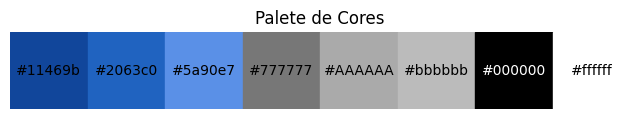

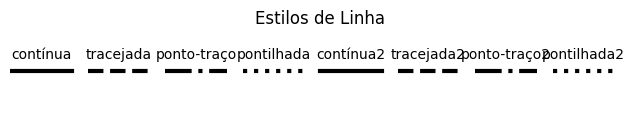

In [16]:
%run "01. Notebooks/00. Configuração/02_Ficheiro Auxiliar.ipynb"

# Visualizar paleta de cores e estilos de linha carregados
if 'mostrar_cores' in globals() and 'PALETA_CORES' in globals():
    mostrar_cores(PALETA_CORES)
if 'mostrar_estilos' in globals() and 'ESTILOS_LINHA' in globals():
    mostrar_estilos(ESTILOS_LINHA)

# 01. Estrutura das Taxas de Juro

**Objetivo:** Análise de cada uma das curvas, de forma a validar a sua estrutura


--- DGS1MO ---
Estatísticas básicas:


count    5004.000000
mean        0.015705
std         0.019219
min         0.000000
25%         0.000500
50%         0.002700
75%         0.026500
max         0.060200
Name: DGS1MO, dtype: float64

Valores nulos: 214
Desses, 198 correspondem a feriados federais dos EUA.
Tabela de datas nulas que NÃO são feriados federais (máx. 20 exemplos):


,observation_date,DGS1MO
59,2005-03-25,NaN
334,2006-04-14,NaN
839,2008-03-21,NaN
1114,2009-04-10,NaN
1644,2011-04-22,NaN
2041,2012-10-30,NaN
2149,2013-03-29,NaN
2424,2014-04-18,NaN
2929,2016-03-25,NaN
3204,2017-04-14,NaN


Valores zero: 100
Datas duplicadas: 0
Gaps relevantes (>1 dia útil não feriado): 0
Outliers (IQR): 0


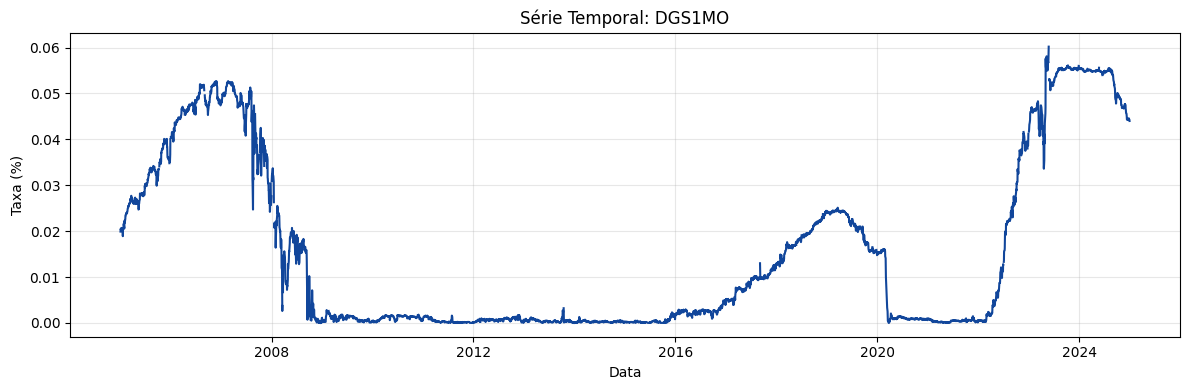

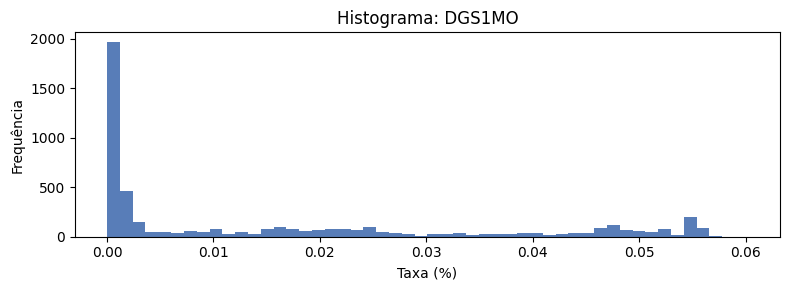


--- DGS3MO ---
Estatísticas básicas:


count    5004.000000
mean        0.016399
std         0.019400
min         0.000000
25%         0.000800
50%         0.003800
75%         0.029100
max         0.056300
Name: DGS3MO, dtype: float64

Valores nulos: 214
Desses, 198 correspondem a feriados federais dos EUA.
Tabela de datas nulas que NÃO são feriados federais (máx. 20 exemplos):


,observation_date,DGS3MO
59,2005-03-25,NaN
334,2006-04-14,NaN
839,2008-03-21,NaN
1114,2009-04-10,NaN
1644,2011-04-22,NaN
2041,2012-10-30,NaN
2149,2013-03-29,NaN
2424,2014-04-18,NaN
2929,2016-03-25,NaN
3204,2017-04-14,NaN


Valores zero: 21
Datas duplicadas: 0
Gaps relevantes (>1 dia útil não feriado): 0
Outliers (IQR): 0


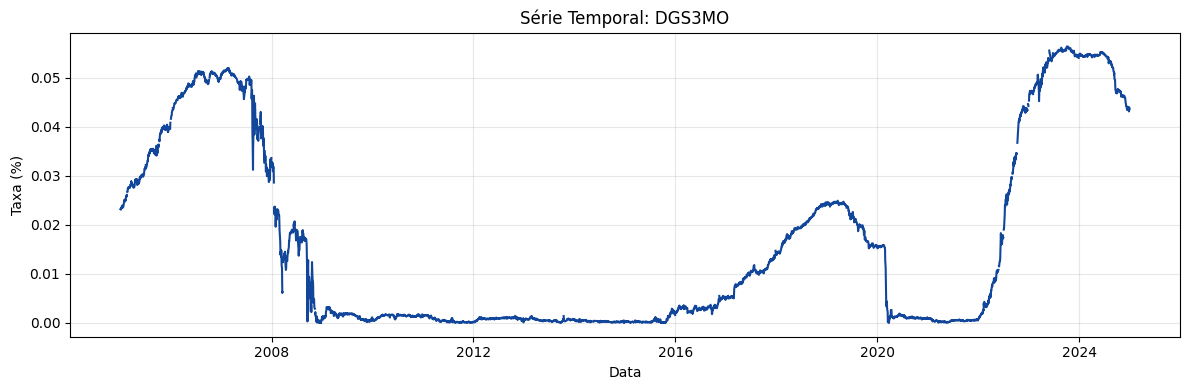

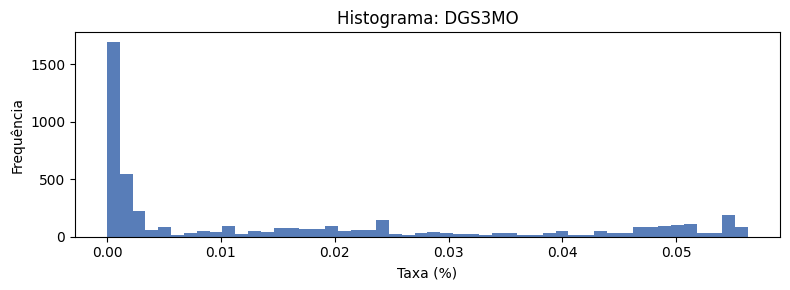


--- DGS6MO ---
Estatísticas básicas:


count    5004.000000
mean        0.017401
std         0.019364
min         0.000200
25%         0.001300
50%         0.006200
75%         0.031700
max         0.056100
Name: DGS6MO, dtype: float64

Valores nulos: 214
Desses, 198 correspondem a feriados federais dos EUA.
Tabela de datas nulas que NÃO são feriados federais (máx. 20 exemplos):


,observation_date,DGS6MO
59,2005-03-25,NaN
334,2006-04-14,NaN
839,2008-03-21,NaN
1114,2009-04-10,NaN
1644,2011-04-22,NaN
2041,2012-10-30,NaN
2149,2013-03-29,NaN
2424,2014-04-18,NaN
2929,2016-03-25,NaN
3204,2017-04-14,NaN


Valores zero: 0
Datas duplicadas: 0
Gaps relevantes (>1 dia útil não feriado): 0
Outliers (IQR): 0


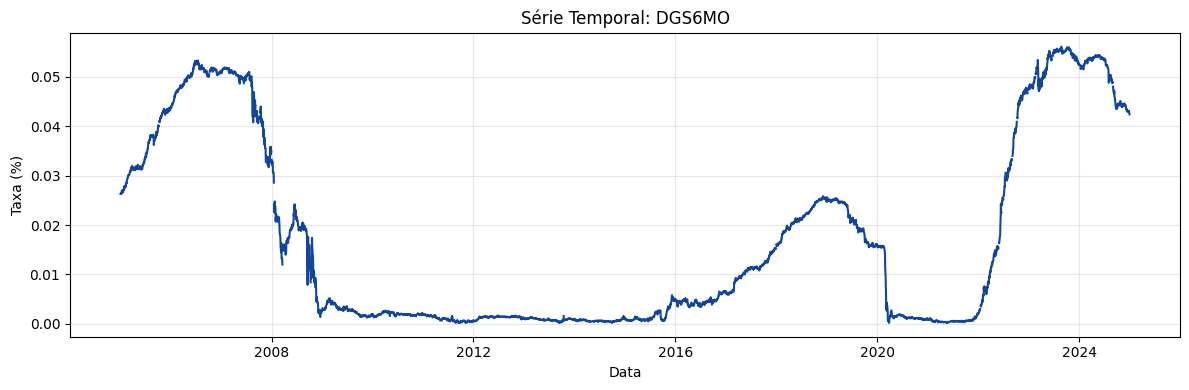

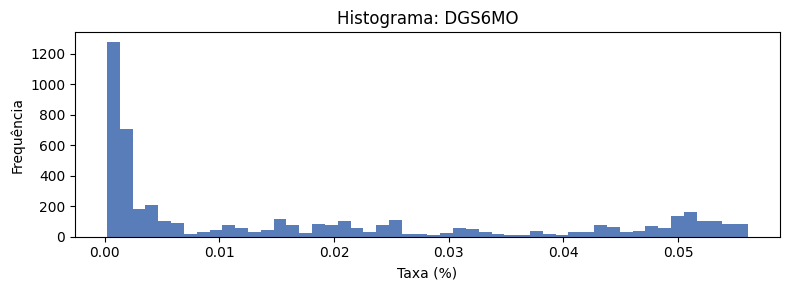


--- DGS1 ---
Estatísticas básicas:


count    5004.000000
mean        0.017929
std         0.018515
min         0.000400
25%         0.001900
50%         0.008200
75%         0.033100
max         0.054900
Name: DGS1, dtype: float64

Valores nulos: 214
Desses, 198 correspondem a feriados federais dos EUA.
Tabela de datas nulas que NÃO são feriados federais (máx. 20 exemplos):


,observation_date,DGS1
59,2005-03-25,NaN
334,2006-04-14,NaN
839,2008-03-21,NaN
1114,2009-04-10,NaN
1644,2011-04-22,NaN
2041,2012-10-30,NaN
2149,2013-03-29,NaN
2424,2014-04-18,NaN
2929,2016-03-25,NaN
3204,2017-04-14,NaN


Valores zero: 0
Datas duplicadas: 0
Gaps relevantes (>1 dia útil não feriado): 0
Outliers (IQR): 0


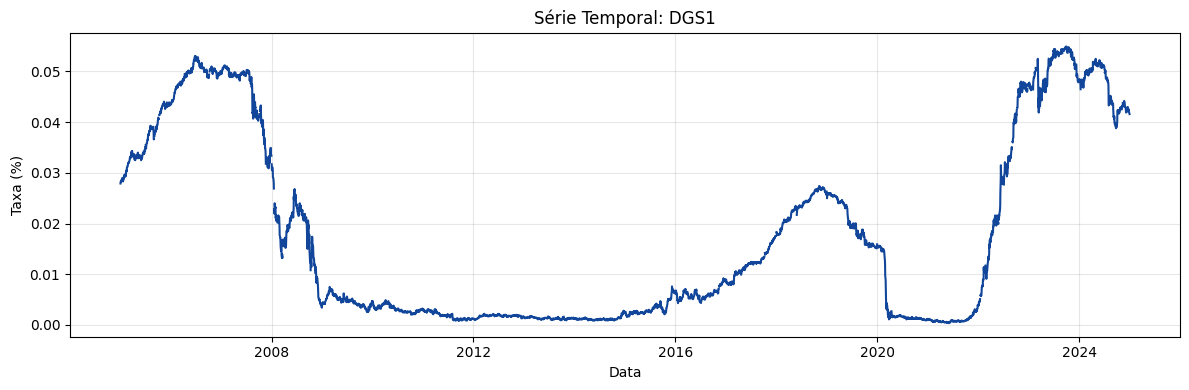

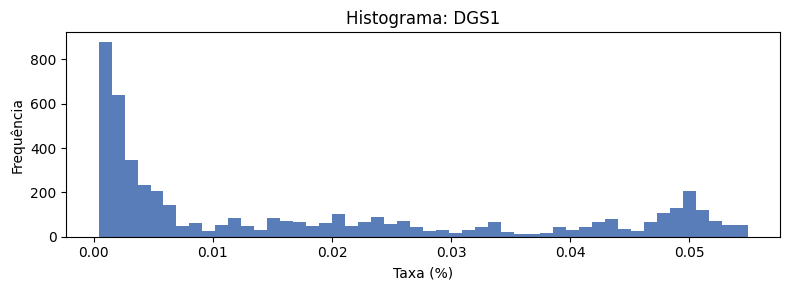

In [17]:
# Análise exploratória das séries de taxas de juro do FRED
us_holidays = holidays.US()
def analisar_serie(df, nome_col, nome_taxa):
    print(f'\n--- {nome_taxa} ---')
    # 1. Estatísticas básicas
    print('Estatísticas básicas:')
    display(df[nome_col].describe())

    # 2. Verificar valores nulos
    n_nulos = df[nome_col].isnull().sum()
    print(f'Valores nulos: {n_nulos}')
    if n_nulos > 0:
        df_nulos = df[df[nome_col].isnull()]
        n_nulos_feriado = df_nulos['observation_date'].apply(lambda d: d in us_holidays).sum()
        print(f'Desses, {n_nulos_feriado} correspondem a feriados federais dos EUA.')
        # Exibir tabela com exemplos apenas dos nulos que não são feriados
        df_nulos_nao_feriado = df_nulos[~df_nulos['observation_date'].apply(lambda d: d in us_holidays)]
        if not df_nulos_nao_feriado.empty:
            print('Tabela de datas nulas que NÃO são feriados federais (máx. 20 exemplos):')
            display(df_nulos_nao_feriado[['observation_date', nome_col]].head(20))
        else:
            print('Todos os nulos coincidem com feriados federais.')

    # 3. Verificar valores zero
    n_zeros = (df[nome_col] == 0).sum()
    print(f'Valores zero: {n_zeros}')

    # 4. Verificar duplicados de data
    n_dupl = df['observation_date'].duplicated().sum()
    print(f'Datas duplicadas: {n_dupl}')
    if n_dupl > 0:
        print('Exemplos de duplicados:')
        display(df[df['observation_date'].duplicated(keep=False)].head(5))

    # 5. Verificar gaps de datas (dias úteis não feriado sem observação)
    datas = pd.to_datetime(df['observation_date'])
    datas_ordenadas = datas.sort_values().reset_index(drop=True)
    gaps = datas_ordenadas.diff().dt.days.dropna()
    gaps_maiores = gaps[gaps > 1]
    gaps_relevantes = []
    for i, gap in enumerate(gaps_maiores):
        data_anterior = datas_ordenadas.iloc[i]
        data_gap = datas_ordenadas.iloc[i+1]
        dias_faltantes = pd.date_range(data_anterior + pd.Timedelta(days=1), data_gap - pd.Timedelta(days=1))
        dias_uteis_nao_feriado = [d for d in dias_faltantes if d.weekday() < 5 and d not in us_holidays]
        if len(dias_uteis_nao_feriado) > 0:
            gaps_relevantes.append((data_anterior, data_gap, dias_uteis_nao_feriado))
    print(f'Gaps relevantes (>1 dia útil não feriado): {len(gaps_relevantes)}')
    if len(gaps_relevantes) > 0:
        for g in gaps_relevantes[:5]:
            print(f'Gap entre {g[0].date()} e {g[1].date()} - Dias úteis faltantes: {len(g[2])}, Exemplos: {[d.date() for d in g[2][:5]]}')

    # 6. Outliers (valores fora do intervalo típico)
    q1 = df[nome_col].quantile(0.25)
    q3 = df[nome_col].quantile(0.75)
    iqr = q3 - q1
    outliers = df[(df[nome_col] < (q1 - 1.5 * iqr)) | (df[nome_col] > (q3 + 1.5 * iqr))]
    print(f'Outliers (IQR): {len(outliers)}')

    # 7. Gráfico da série temporal
    plt.figure(figsize=(12, 4))
    plt.plot(df['observation_date'], df[nome_col], label=nome_taxa, color=COLOR_AZUL1, linestyle='-')
    plt.title(f'Série Temporal: {nome_taxa}')
    plt.xlabel('Data')
    plt.ylabel('Taxa (%)')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    caminho_export = os.path.join(DIR_GRAFICOS, f"{nome_taxa}_serie_temporal.png")
    plt.savefig(caminho_export, dpi=150)
    plt.show()

    # 8. Histograma
    plt.figure(figsize=(8, 3))
    plt.hist(df[nome_col].dropna(), bins=50, color=COLOR_AZUL1, alpha=0.7)
    plt.title(f'Histograma: {nome_taxa}')
    plt.xlabel('Taxa (%)')
    plt.ylabel('Frequência')
    plt.tight_layout()
    plt.show()

    # # 9. Boxplot
    # plt.figure(figsize=(4, 3))
    # sns.boxplot(y=df[nome_col], color=COLOR_AZUL1)
    # plt.title(f'Boxplot: {nome_taxa}')
    # plt.ylabel('Taxa (%)')
    # plt.tight_layout()
    # plt.show()

# Executar análise para cada série
analisar_serie(df_dgs1mo, 'DGS1MO', 'DGS1MO')
analisar_serie(df_dgs3mo, 'DGS3MO', 'DGS3MO')
analisar_serie(df_dgs6mo, 'DGS6MO', 'DGS6MO')
analisar_serie(df_dgs1, 'DGS1', 'DGS1')

# 02. Merge das Taxas de Juro em Dataframe único

**Objetivo:** Criação de um dataframe único com as taxas de juro a usar

In [18]:
# 1) Validar que todas as taxas têm as mesmas observation_date (mesmo número de entradas)
print('Tamanhos:',
      'DGS1MO:', len(df_dgs1mo),
      'DGS3MO:', len(df_dgs3mo),
      'DGS6MO:', len(df_dgs6mo),
      'DGS1:', len(df_dgs1))
iguais = (len(df_dgs1mo) == len(df_dgs3mo) == len(df_dgs6mo) == len(df_dgs1))
print('Todas as séries têm o mesmo número de datas?', iguais)
if not iguais:
    print('Atenção: As séries não têm o mesmo número de datas!')
else:
    # 2) Merge das 4 taxas de juro num dataframe único
    df_IR_1 = df_dgs1mo[['observation_date', 'DGS1MO']].merge(
        df_dgs3mo[['observation_date', 'DGS3MO']], on='observation_date', how='inner'
    ).merge(
        df_dgs6mo[['observation_date', 'DGS6MO']], on='observation_date', how='inner'
    ).merge(
        df_dgs1[['observation_date', 'DGS1']], on='observation_date', how='inner'
    )
    print('Shape do df_IR_1 após merge:', df_IR_1.shape)

    # 3) Retirar valores nulos
    n_nulos = df_IR_1.isnull().sum().sum()
    print(f'Total de valores nulos antes de drop: {n_nulos}')
    df_IR_1 = df_IR_1.dropna()
    print('Shape após remoção de nulos:', df_IR_1.shape)

    # 4) Validar datas de início e fim e filtrar
    data_inicio = pd.to_datetime('2009-01-02')
    data_fim = pd.to_datetime('2019-04-30')
    tem_inicio = data_inicio in df_IR_1['observation_date'].values
    tem_fim = data_fim in df_IR_1['observation_date'].values
    print(f"Temos 02-01-2009? {tem_inicio}")
    print(f"Temos 30-04-2019? {tem_fim}")
    if tem_inicio and tem_fim:
        df_IR = df_IR_1[(df_IR_1['observation_date'] >= data_inicio) & (df_IR_1['observation_date'] <= data_fim)].copy()
        print('Shape final do df_IR:', df_IR.shape)
    else:
        print('Não foi possível filtrar para o intervalo desejado!')

Tamanhos: DGS1MO: 5218 DGS3MO: 5218 DGS6MO: 5218 DGS1: 5218
Todas as séries têm o mesmo número de datas? True
Shape do df_IR_1 após merge: (5218, 5)
Total de valores nulos antes de drop: 856
Shape após remoção de nulos: (5004, 5)
Temos 02-01-2009? True
Temos 30-04-2019? True
Shape final do df_IR: (2583, 5)


# 03. Análise Final e Save

**Objetivo:** Análise final sobre o dataframe único e save na pasta


--- Análise para DGS1MO no df_IR_1 ---

--- DGS1MO ---
Estatísticas básicas:


count    2583.000000
mean        0.004035
std         0.006688
min         0.000000
25%         0.000300
50%         0.000900
75%         0.002800
max         0.025100
Name: DGS1MO, dtype: float64

Valores nulos: 0
Valores zero: 85
Datas duplicadas: 0
Gaps relevantes (>1 dia útil não feriado): 1
Gap entre 2009-04-09 e 2009-04-13 - Dias úteis faltantes: 1, Exemplos: [datetime.date(2009, 4, 10)]
Outliers (IQR): 534


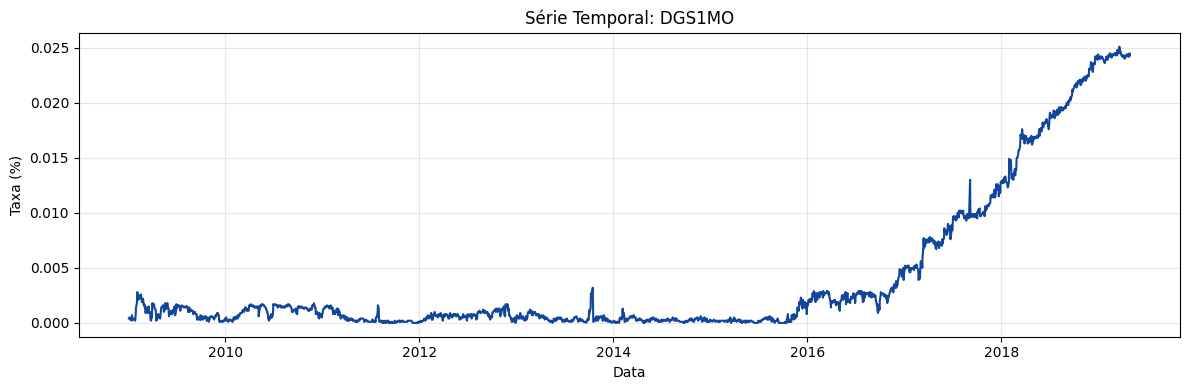

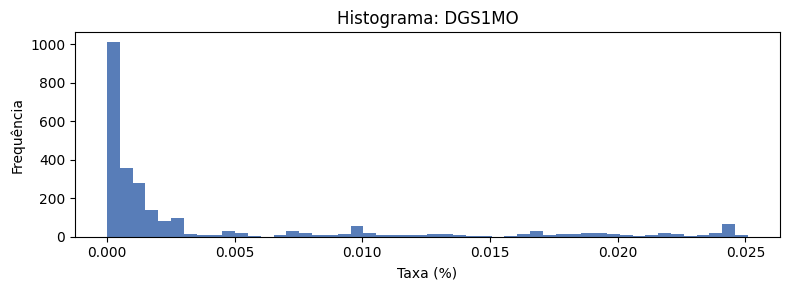


--- Análise para DGS3MO no df_IR_1 ---

--- DGS3MO ---
Estatísticas básicas:


count    2583.000000
mean        0.004456
std         0.006956
min         0.000000
25%         0.000500
50%         0.001200
75%         0.003350
max         0.024900
Name: DGS3MO, dtype: float64

Valores nulos: 0
Valores zero: 16
Datas duplicadas: 0
Gaps relevantes (>1 dia útil não feriado): 1
Gap entre 2009-04-09 e 2009-04-13 - Dias úteis faltantes: 1, Exemplos: [datetime.date(2009, 4, 10)]
Outliers (IQR): 528


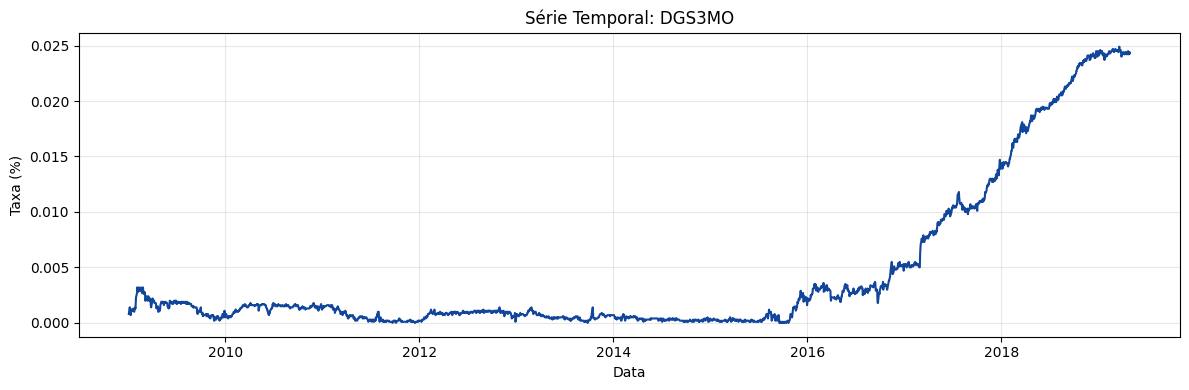

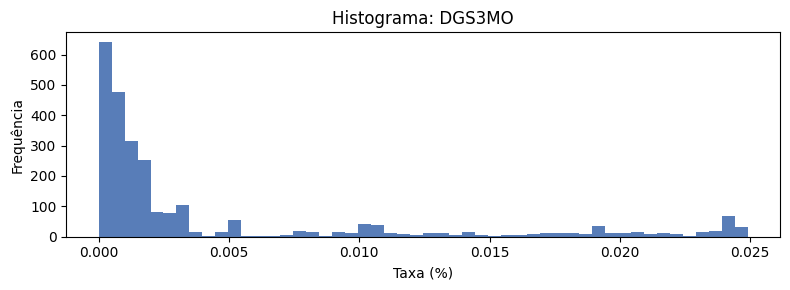


--- Análise para DGS6MO no df_IR_1 ---

--- DGS6MO ---
Estatísticas básicas:


count    2583.000000
mean        0.005339
std         0.007230
min         0.000200
25%         0.001000
50%         0.001800
75%         0.005000
max         0.025800
Name: DGS6MO, dtype: float64

Valores nulos: 0
Valores zero: 0
Datas duplicadas: 0
Gaps relevantes (>1 dia útil não feriado): 1
Gap entre 2009-04-09 e 2009-04-13 - Dias úteis faltantes: 1, Exemplos: [datetime.date(2009, 4, 10)]
Outliers (IQR): 471


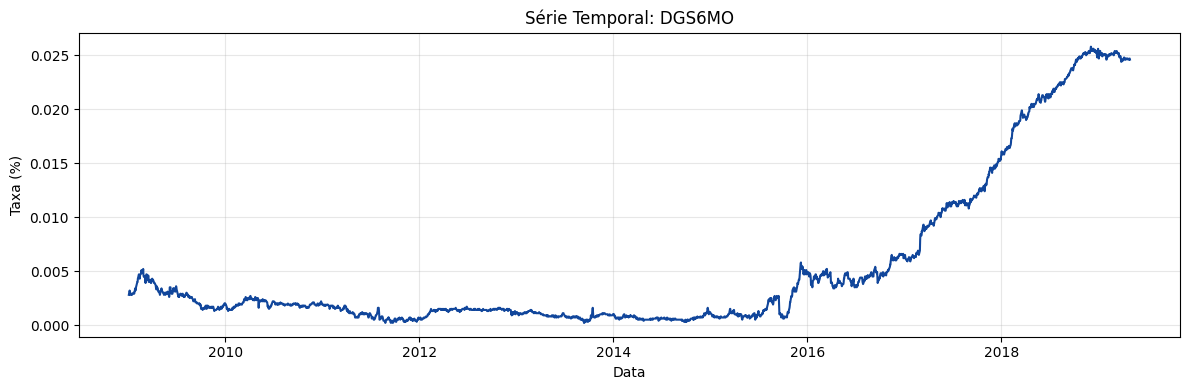

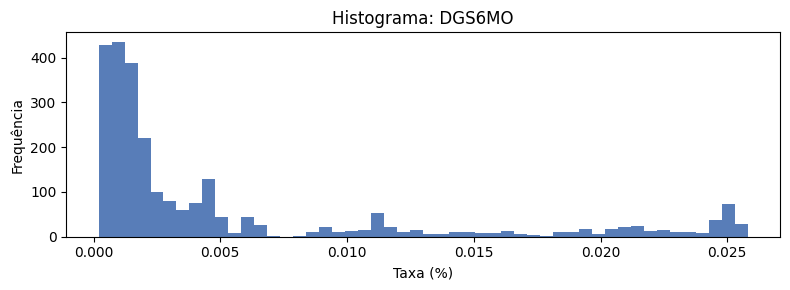


--- Análise para DGS1 no df_IR_1 ---

--- DGS1 ---
Estatísticas básicas:


count    2583.000000
mean        0.006472
std         0.007425
min         0.000800
25%         0.001700
50%         0.003000
75%         0.006800
max         0.027400
Name: DGS1, dtype: float64

Valores nulos: 0
Valores zero: 0
Datas duplicadas: 0
Gaps relevantes (>1 dia útil não feriado): 1
Gap entre 2009-04-09 e 2009-04-13 - Dias úteis faltantes: 1, Exemplos: [datetime.date(2009, 4, 10)]
Outliers (IQR): 372


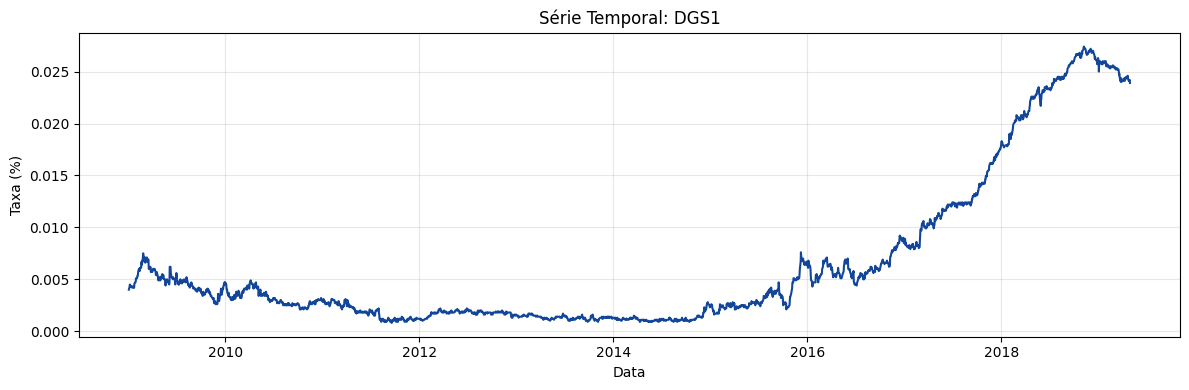

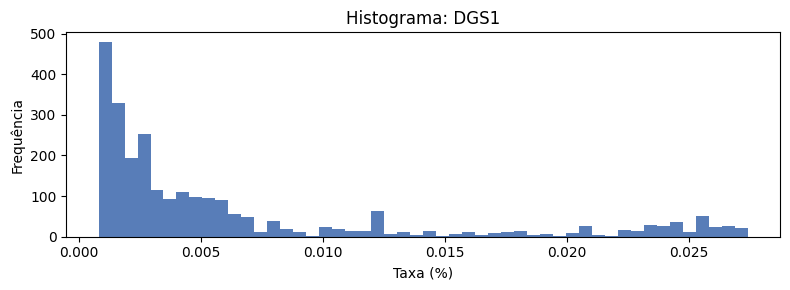

In [20]:
# Repetir as análises para cada série do df_IR_1
for col in ['DGS1MO', 'DGS3MO', 'DGS6MO', 'DGS1']:
    print(f"\n--- Análise para {col} no df_IR_1 ---")
    analisar_serie(df_IR[['observation_date', col]].copy(), col, col)

In [23]:
# Guardar o dataframe final df_IR em formato parquet
caminho_parquet = os.path.join(Dir_OUTPUT, "df_IR.parquet")
df_IR.to_parquet(caminho_parquet, index=False)
print(f"df_IR salvo em: {caminho_parquet}")

df_IR salvo em: 02. Dados/02. Dados Tratados\df_IR.parquet
